# Praktikum Pembelajaran Mesin — Regresi Linear
**Program Studi Teknik Informatika S1**

Notebook ini mengikuti pokok materi Pertemuan 3: regresi linear sederhana dan berganda, koefisien/intercept, residual dan MSE, fitting model, evaluasi MAE–MSE–RMSE–R², pemeriksaan residual, outlier/leverage, multikolinearitas, interpretasi koefisien, serta perbandingan solusi `scikit-learn` dengan Normal Equation.

**Tujuan praktikum**
1. Membentuk model regresi linear dari data.
2. Memisahkan data latih dan data uji sebelum evaluasi.
3. Menghitung dan menafsirkan metrik regresi.
4. Memvisualisasikan garis regresi dan residual.
5. Mengamati pengaruh hubungan non-linear, outlier, dan multikolinearitas.
6. Menghitung koefisien dengan Normal Equation dan membandingkannya dengan model pustaka.

**Cara menjalankan:** buka notebook di Google Colab, lalu pilih *Runtime → Run all*. Sebagian besar contoh memakai data sintetis agar mudah dipahami dan hasilnya dapat direproduksi.

## 1. Persiapan pustaka

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.datasets import fetch_california_housing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

SEED = 42
np.random.seed(SEED)
print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 2. Memahami data: jam belajar dan nilai ujian

Kita gunakan contoh sederhana yang sejalan dengan slide: satu fitur **jam belajar (X)** dan satu target **nilai ujian (Y)**. Data pertama sengaja dibuat kecil agar mudah diperiksa.

In [2]:
data_kecil = pd.DataFrame({
    "Nama": ["Andi", "Budi", "Cici"],
    "Jam_Belajar": [2, 4, 6],
    "Nilai_Ujian": [65, 75, 85]
})
display(data_kecil)

,Nama,Jam_Belajar,Nilai_Ujian
0,Andi,2,65
1,Budi,4,75
2,Cici,6,85


### Latihan singkat 1
Tanpa menjalankan model, menurut Anda apakah hubungan kedua variabel ini positif atau negatif? Apakah ketiga titik berada tepat pada satu garis?

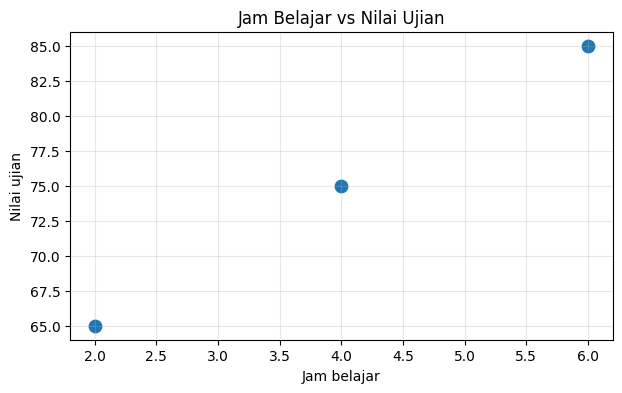

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(data_kecil["Jam_Belajar"], data_kecil["Nilai_Ujian"], s=80)
plt.xlabel("Jam belajar")
plt.ylabel("Nilai ujian")
plt.title("Jam Belajar vs Nilai Ujian")
plt.grid(alpha=0.3)
plt.show()

## 3. Fitting regresi linear sederhana

Model: \(\hat{y} = \beta_0 + \beta_1 x\)

- **Intercept** (β₀): prediksi target saat X = 0.
- **Koefisien/slope** (β₁): perubahan prediksi target untuk setiap kenaikan satu unit X.
- **Residual**: nilai aktual − nilai prediksi.

In [4]:
X = data_kecil[["Jam_Belajar"]]
y = data_kecil["Nilai_Ujian"]

model_kecil = LinearRegression()
model_kecil.fit(X, y)

print(f"Intercept (β0): {model_kecil.intercept_:.2f}")
print(f"Koefisien (β1): {model_kecil.coef_[0]:.2f}")
print(f"Persamaan: ŷ = {model_kecil.intercept_:.2f} + {model_kecil.coef_[0]:.2f}x")

data_kecil["Prediksi"] = model_kecil.predict(X)
data_kecil["Residual"] = data_kecil["Nilai_Ujian"] - data_kecil["Prediksi"]
display(data_kecil)

Intercept (β0): 55.00
Koefisien (β1): 5.00
Persamaan: ŷ = 55.00 + 5.00x


,Nama,Jam_Belajar,Nilai_Ujian,Prediksi,Residual
0,Andi,2,65,65.0,0.0
1,Budi,4,75,75.0,0.0
2,Cici,6,85,85.0,0.0


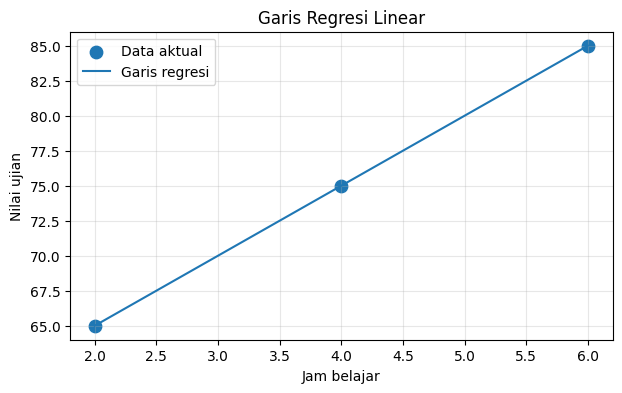

In [5]:
x_garis = np.linspace(data_kecil["Jam_Belajar"].min(), data_kecil["Jam_Belajar"].max(), 100)
y_garis = model_kecil.predict(pd.DataFrame({"Jam_Belajar": x_garis}))

plt.figure(figsize=(7, 4))
plt.scatter(data_kecil["Jam_Belajar"], data_kecil["Nilai_Ujian"], label="Data aktual", s=80)
plt.plot(x_garis, y_garis, label="Garis regresi")
plt.xlabel("Jam belajar")
plt.ylabel("Nilai ujian")
plt.title("Garis Regresi Linear")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Prediksi untuk data baru

Prediksi adalah estimasi model, bukan jaminan nilai sebenarnya. Hindari menafsirkan prediksi di luar rentang data latih secara berlebihan.

In [6]:
data_baru = pd.DataFrame({"Jam_Belajar": [3, 5, 7]})
data_baru["Prediksi_Nilai"] = model_kecil.predict(data_baru)
display(data_baru)

,Jam_Belajar,Prediksi_Nilai
0,3,70.0
1,5,80.0
2,7,90.0


## 4. Normal Equation: menghitung koefisien secara langsung

Untuk model linear dengan intercept, Normal Equation dapat ditulis:
\[
\beta = (X^T X)^{-1}X^T y
\]
Dalam praktik komputasi, `np.linalg.lstsq` lebih aman daripada menghitung invers secara eksplisit.

In [7]:
X_np = data_kecil[["Jam_Belajar"]].to_numpy()
y_np = data_kecil["Nilai_Ujian"].to_numpy()
X_design = np.column_stack([np.ones(len(X_np)), X_np])  # kolom 1 untuk intercept

beta, residuals, rank, singular_values = np.linalg.lstsq(X_design, y_np, rcond=None)
print("Normal Equation / least squares:")
print(f"β0 = {beta[0]:.2f}")
print(f"β1 = {beta[1]:.2f}")

print("\nPerbandingan dengan scikit-learn:")
print(f"Intercept sklearn = {model_kecil.intercept_:.2f}")
print(f"Koefisien sklearn = {model_kecil.coef_[0]:.2f}")

Normal Equation / least squares:
β0 = 55.00
β1 = 5.00

Perbandingan dengan scikit-learn:
Intercept sklearn = 55.00
Koefisien sklearn = 5.00


## 5. Loss dan metrik evaluasi: MSE, RMSE, MAE, dan R²

Agar evaluasi tidak hanya mengukur kemampuan model mengingat data, kita pisahkan data menjadi **train** dan **test**. Model hanya dilatih pada train; metrik akhir dihitung pada test.

In [8]:
# Membuat data sintetis yang memiliki sedikit variasi/noise
rng = np.random.default_rng(SEED)
n = 100
jam = rng.uniform(1, 10, n)
nilai = 50 + 4.5 * jam + rng.normal(0, 6, n)
df = pd.DataFrame({"Jam_Belajar": jam, "Nilai_Ujian": nilai})

X = df[["Jam_Belajar"]]
y = df["Nilai_Ujian"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Jumlah data train: {len(X_train)}")
print(f"Jumlah data test : {len(X_test)}")
print(f"MSE  = {mse:.3f}")
print(f"RMSE = {rmse:.3f} poin")
print(f"MAE  = {mae:.3f} poin")
print(f"R²   = {r2:.3f}")

Jumlah data train: 75
Jumlah data test : 25
MSE  = 26.395
RMSE = 5.138 poin
MAE  = 3.984 poin
R²   = 0.799


**Panduan interpretasi**
- MSE mengkuadratkan residual sehingga kesalahan besar mendapat penalti lebih besar.
- RMSE adalah akar MSE dan memakai satuan target (di sini poin nilai).
- MAE adalah rata-rata besar kesalahan absolut; relatif lebih tidak sensitif terhadap error ekstrem dibanding RMSE.
- R² mengukur performa relatif terhadap baseline rata-rata. R² dapat negatif pada data uji jika model lebih buruk daripada baseline tersebut.

Tidak ada ambang “baik” yang berlaku untuk semua kasus. Bandingkan metrik dengan konteks masalah dan baseline yang masuk akal.

In [9]:
hasil_uji = pd.DataFrame({
    "Aktual": y_test.to_numpy(),
    "Prediksi": y_pred,
})
hasil_uji["Residual (aktual - prediksi)"] = hasil_uji["Aktual"] - hasil_uji["Prediksi"]
display(hasil_uji.head(10))

,Aktual,Prediksi,Residual (aktual - prediksi)
0,62.578698,61.060492,1.518206
1,75.212537,82.068765,-6.856227
2,62.250852,63.069500,-0.818648
3,88.699225,87.972503,0.726722
4,75.414244,89.132690,-13.718446
5,86.656226,82.278187,4.378039
6,87.672285,94.974178,-7.301893
7,80.692868,82.046092,-1.353224
8,74.559169,69.661020,4.898148
9,88.243865,86.672527,1.571338


## 6. Plot prediksi dan residual

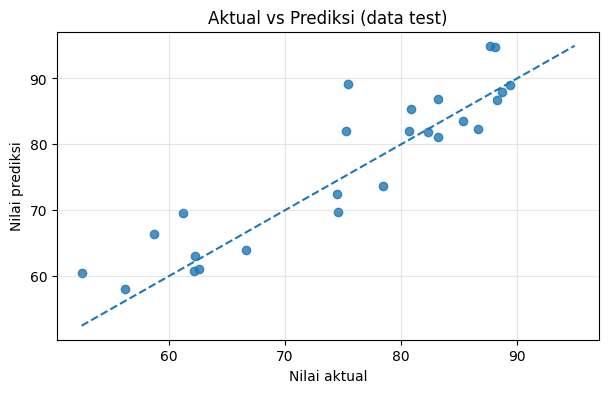

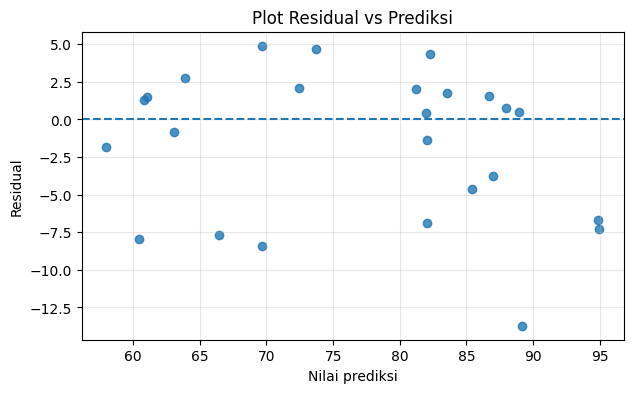

In [10]:
plt.figure(figsize=(7, 4))
plt.scatter(y_test, y_pred, alpha=0.8)
batas_min = min(y_test.min(), y_pred.min())
batas_maks = max(y_test.max(), y_pred.max())
plt.plot([batas_min, batas_maks], [batas_min, batas_maks], linestyle="--")
plt.xlabel("Nilai aktual")
plt.ylabel("Nilai prediksi")
plt.title("Aktual vs Prediksi (data test)")
plt.grid(alpha=0.3)
plt.show()

residual = y_test.to_numpy() - y_pred
plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residual, alpha=0.8)
plt.axhline(0, linestyle="--")
plt.xlabel("Nilai prediksi")
plt.ylabel("Residual")
plt.title("Plot Residual vs Prediksi")
plt.grid(alpha=0.3)
plt.show()

**Pertanyaan interpretasi**
1. Apakah residual tersebar relatif acak di sekitar nol?
2. Apakah terlihat pola melengkung atau pola kipas?
3. Apa arti pola residual yang sistematis bagi asumsi linearitas atau variasi error?

Plot residual membantu diagnosis, tetapi tidak sendirian membuktikan semua asumsi model terpenuhi.

## 7. Hubungan non-linear: bandingkan model linear dan polynomial

Jika pola sebenarnya melengkung, garis lurus mungkin tidak cukup. Kita bandingkan model linear dengan regresi polynomial derajat 2. Polynomial regression tetap linear terhadap koefisien, tetapi memakai fitur seperti \(x^2\).

Linear                   | RMSE=9.17 | R²=0.924
Polynomial derajat 2     | RMSE=5.96 | R²=0.968


C:\Users\GIOVANI DAVINCI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\GIOVANI DAVINCI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


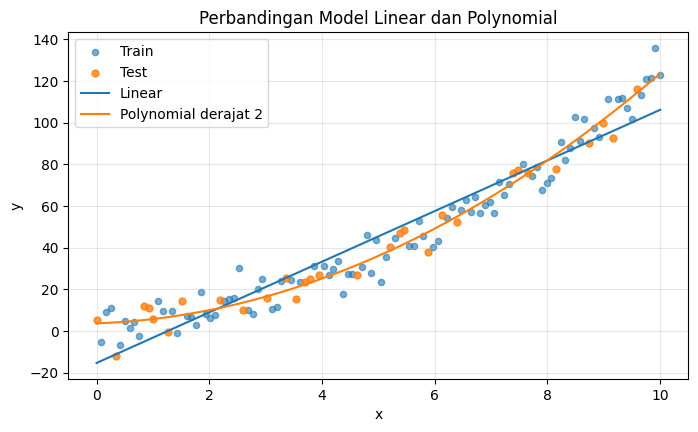

In [11]:
rng = np.random.default_rng(SEED)
x = np.linspace(0, 10, 120)
y_curve = 3 + 1.2*x + 1.1*(x**2) + rng.normal(0, 8, len(x))
df_curve = pd.DataFrame({"x": x, "y": y_curve})

Xtr, Xte, ytr, yte = train_test_split(
    df_curve[["x"]], df_curve["y"], test_size=0.25, random_state=SEED
)

linear = Pipeline([("model", LinearRegression())])
poly2 = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])
linear.fit(Xtr, ytr)
poly2.fit(Xtr, ytr)

for nama, mdl in [("Linear", linear), ("Polynomial derajat 2", poly2)]:
    pred = mdl.predict(Xte)
    print(f"{nama:24s} | RMSE={np.sqrt(mean_squared_error(yte, pred)):.2f} | R²={r2_score(yte, pred):.3f}")

x_plot = np.linspace(0, 10, 200).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.scatter(Xtr["x"], ytr, s=20, alpha=0.6, label="Train")
plt.scatter(Xte["x"], yte, s=25, alpha=0.8, label="Test")
plt.plot(x_plot.ravel(), linear.predict(x_plot), label="Linear")
plt.plot(x_plot.ravel(), poly2.predict(x_plot), label="Polynomial derajat 2")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Perbandingan Model Linear dan Polynomial")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Diskusi:** model mana yang memperoleh RMSE test lebih rendah? Apakah kompleksitas lebih tinggi selalu lebih baik? Jelaskan berdasarkan hasil, bukan hanya berdasarkan bentuk garis.

## 8. Dampak outlier pada target

Satu nilai target ekstrem dapat menarik garis regresi dan memperbesar MSE/RMSE. Pada contoh ini kita bandingkan model dengan dan tanpa satu titik ekstrem. Jangan otomatis menghapus outlier: periksa apakah data salah, kejadian nyata, atau bagian penting dari populasi.

Tanpa outlier: intercept=39.10, slope=3.08
Dengan outlier: intercept=37.59, slope=3.29


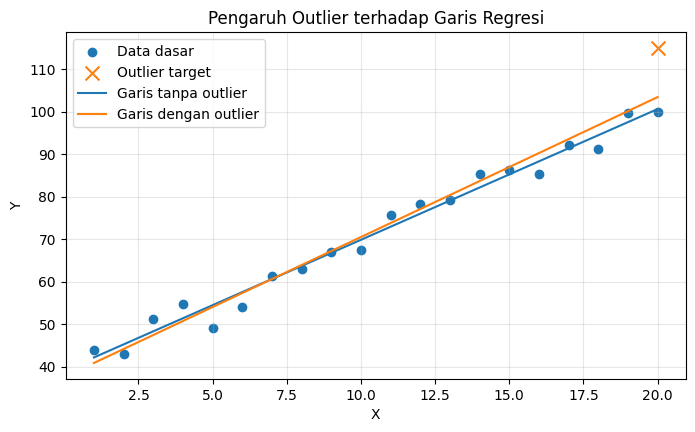

In [12]:
rng = np.random.default_rng(SEED)
x = np.arange(1, 21, dtype=float)
y = 40 + 3*x + rng.normal(0, 3, len(x))
y_outlier = y.copy()
y_outlier[-1] = 115  # satu target ekstrem untuk demonstrasi

m_normal = LinearRegression().fit(x.reshape(-1, 1), y)
m_out = LinearRegression().fit(x.reshape(-1, 1), y_outlier)

print(f"Tanpa outlier: intercept={m_normal.intercept_:.2f}, slope={m_normal.coef_[0]:.2f}")
print(f"Dengan outlier: intercept={m_out.intercept_:.2f}, slope={m_out.coef_[0]:.2f}")

xx = np.linspace(1, 20, 100).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.scatter(x, y, label="Data dasar")
plt.scatter([x[-1]], [y_outlier[-1]], label="Outlier target", marker="x", s=100)
plt.plot(xx, m_normal.predict(xx), label="Garis tanpa outlier")
plt.plot(xx, m_out.predict(xx), label="Garis dengan outlier")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Pengaruh Outlier terhadap Garis Regresi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Catatan tentang leverage
Leverage berkaitan dengan posisi ekstrem pada fitur X; titik seperti ini dapat berpengaruh besar pada garis regresi. Di analisis regresi yang lebih mendalam, hat values dan Cook's distance dapat membantu mengidentifikasi observasi yang berpengaruh. Praktikum ini baru mengilustrasikan pengaruh titik ekstrem secara visual.

## 9. Regresi linear berganda dan multikolinearitas

Regresi berganda memakai lebih dari satu fitur, misalnya jam belajar dan kehadiran untuk memprediksi nilai. Koefisien diinterpretasikan sebagai perubahan prediksi ketika satu fitur naik satu unit **dengan fitur lain dianggap tetap**.

In [13]:
rng = np.random.default_rng(SEED)
n = 160
jam = rng.uniform(1, 10, n)
kehadiran = rng.uniform(60, 100, n)
nilai = 35 + 4.2*jam + 0.25*kehadiran + rng.normal(0, 5, n)

df_multi = pd.DataFrame({
    "Jam_Belajar": jam,
    "Kehadiran": kehadiran,
    "Nilai_Ujian": nilai
})
X = df_multi[["Jam_Belajar", "Kehadiran"]]
y = df_multi["Nilai_Ujian"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED)

multi = LinearRegression().fit(Xtr, ytr)
pred = multi.predict(Xte)
print(f"Intercept: {multi.intercept_:.3f}")
for fitur, koef in zip(X.columns, multi.coef_):
    print(f"Koefisien {fitur}: {koef:.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(yte, pred)):.3f}")
print(f"Test R²  : {r2_score(yte, pred):.3f}")

Intercept: 31.492
Koefisien Jam_Belajar: 4.326
Koefisien Kehadiran: 0.289
Test RMSE: 4.675
Test R²  : 0.846


### Demonstrasi multikolinearitas
Buat fitur kedua yang hampir merupakan salinan linear dari fitur pertama. Prediksi bisa tetap cukup baik, tetapi koefisien individual dapat menjadi tidak stabil atau sulit diinterpretasikan.

In [14]:
rng = np.random.default_rng(SEED)
n = 150
x1 = rng.normal(50, 10, n)
x2 = 2*x1 + rng.normal(0, 0.5, n)  # sangat berkorelasi dengan x1
y = 10 + 1.5*x1 + rng.normal(0, 5, n)

X_corr = pd.DataFrame({"Fitur_A": x1, "Fitur_B_hampir_duplikat": x2})
print("Korelasi antarf fitur:")
display(X_corr.corr())

Xtr, Xte, ytr, yte = train_test_split(X_corr, y, test_size=0.25, random_state=SEED)
mdl_corr = LinearRegression().fit(Xtr, ytr)
print("Koefisien:", dict(zip(X_corr.columns, mdl_corr.coef_)))
print("Test R²:", round(r2_score(yte, mdl_corr.predict(Xte)), 3))
print("Catatan: jangan menyimpulkan pentingnya fitur hanya dari besar koefisien ketika fitur sangat berkorelasi.")

Korelasi antarf fitur:


,Fitur_A,Fitur_B_hampir_duplikat
Fitur_A,1.000000,0.999575
Fitur_B_hampir_duplikat,0.999575,1.000000


Koefisien: {'Fitur_A': np.float64(5.27852543399463), 'Fitur_B_hampir_duplikat': np.float64(-1.8991440882764408)}
Test R²: 0.827
Catatan: jangan menyimpulkan pentingnya fitur hanya dari besar koefisien ketika fitur sangat berkorelasi.


## 10. Interpretasi koefisien dan skala fitur

Tanda koefisien menunjukkan arah hubungan yang dipelajari model, tetapi tidak otomatis membuktikan sebab-akibat. Besar koefisien antarfitur tidak bisa dibandingkan langsung jika skala/satuan fiturnya berbeda. Standardisasi dapat membantu perbandingan skala, khususnya untuk model yang sensitif terhadap skala.

In [15]:
# Contoh ringkas: standardisasi hanya pada fitur, dengan pipeline agar transformasi konsisten
pipe_std = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
pipe_std.fit(Xtr, ytr)
print("Koefisien pada fitur terstandardisasi:", pipe_std.named_steps["model"].coef_)

Koefisien pada fitur terstandardisasi: [ 45.82198361 -32.99734249]


## 11. Eksplorasi dataset nyata: California Housing (opsional)

Bagian ini mencoba dataset California Housing dari scikit-learn. Dataset mungkin perlu diunduh saat pertama kali dijalankan dan memerlukan koneksi internet. Jika gagal, lewati bagian ini; bagian sebelumnya tetap dapat digunakan.

In [16]:
try:
    housing = fetch_california_housing(as_frame=True)
    Xh = housing.data
    yh = housing.target

    X_train, X_test, y_train, y_test = train_test_split(
        Xh, yh, test_size=0.2, random_state=SEED
    )
    housing_model = LinearRegression()
    housing_model.fit(X_train, y_train)
    yh_pred = housing_model.predict(X_test)

    print(f"Jumlah fitur: {Xh.shape[1]}")
    print(f"RMSE test: {np.sqrt(mean_squared_error(y_test, yh_pred)):.3f}")
    print(f"MAE test : {mean_absolute_error(y_test, yh_pred):.3f}")
    print(f"R² test  : {r2_score(y_test, yh_pred):.3f}")

    coef_table = pd.DataFrame({
        "Fitur": Xh.columns,
        "Koefisien": housing_model.coef_
    })
    coef_table["Nilai_absolut"] = coef_table["Koefisien"].abs()
    display(coef_table.sort_values("Nilai_absolut", ascending=False))
except Exception as e:
    print("Dataset opsional tidak berhasil dimuat.")
    print("Silakan lewati bagian ini atau periksa koneksi internet.")
    print("Pesan teknis:", repr(e))

Jumlah fitur: 8
RMSE test: 0.746
MAE test : 0.533
R² test  : 0.576


,Fitur,Koefisien,Nilai_absolut
3,AveBedrms,0.783145,0.783145
0,MedInc,0.448675,0.448675
7,Longitude,-0.433708,0.433708
6,Latitude,-0.419792,0.419792
2,AveRooms,-0.123323,0.123323
1,HouseAge,0.009724,0.009724
5,AveOccup,-0.003526,0.003526
4,Population,-0.000002,0.000002


## 12. Tugas praktikum mahasiswa

Kerjakan dan kumpulkan notebook yang telah dilengkapi jawaban/komentar pada sel Markdown.

### Tugas A — Eksperimen model
1. Ubah `test_size` menjadi 0.20 lalu 0.30. Catat RMSE, MAE, dan R².
2. Jalankan ulang dengan `random_state=7`. Apakah metrik berubah? Jelaskan.
3. Bandingkan koefisien dan intercept untuk setiap percobaan.

### Tugas B — Diagnostik
4. Amati plot residual model pada Bagian 6. Jelaskan apakah terlihat pola sistematis.
5. Pada Bagian 7, bandingkan model linear dan polynomial berdasarkan metrik data test.
6. Pada Bagian 8, jelaskan perubahan slope ketika outlier ditambahkan.

### Tugas C — Interpretasi
7. Jelaskan makna intercept dan koefisien pada regresi berganda Bagian 9.
8. Mengapa multikolinearitas menyulitkan interpretasi koefisien?
9. Jelaskan perbedaan MAE dan RMSE serta kapan masing-masing berguna.
10. Tulis 1–2 paragraf insight berdasarkan hasil eksperimen, bukan hanya menyalin angka.

### Format laporan
- Tujuan eksperimen.
- Langkah dan perubahan parameter.
- Tabel metrik train/test bila relevan.
- Minimal satu plot.
- Kesimpulan dan keterbatasan.

**Pengingat:** jangan memilih model hanya dari performa training. Gunakan data test untuk menilai kemampuan generalisasi.

### Tugas A — Eksperimen Model

Berikut adalah implementasi eksperimen untuk membandingkan variasi nilai `test_size` (0.20 dan 0.30) serta `random_state` (42 dan 7) pada model regresi linear (menggunakan data `Jam_Belajar` dan `Nilai_Ujian` dari Bagian 5).


In [25]:
# ==========================================
# Eksperimen Model Regresi Linear (Tugas A)
# ==========================================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Daftar konfigurasi eksperimen
daftar_eksperimen = [
    ('Baseline (Bagian 5)', 0.25, 42),
    ('Eksperimen 1 (test_size=0.20, seed=42)', 0.20, 42),
    ('Eksperimen 2 (test_size=0.30, seed=42)', 0.30, 42),
    ('Eksperimen 3 (test_size=0.20, seed=7)', 0.20, 7),
    ('Eksperimen 4 (test_size=0.30, seed=7)', 0.30, 7),
    ('Eksperimen 5 (test_size=0.25, seed=7)', 0.25, 7)
]

hasil_tugas_a = []
for label, ts, rs in daftar_eksperimen:
    # Split data latih dan data uji
    X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
        X, y, test_size=ts, random_state=rs
    )
    
    # Inisialisasi dan fitting model
    mdl = LinearRegression()
    mdl.fit(X_train_exp, y_train_exp)
    
    # Prediksi data uji
    y_pred_exp = mdl.predict(X_test_exp)
    
    # Hitung metrik evaluasi
    mse_val = mean_squared_error(y_test_exp, y_pred_exp)
    rmse_val = np.sqrt(mse_val)
    mae_val = mean_absolute_error(y_test_exp, y_pred_exp)
    r2_val = r2_score(y_test_exp, y_pred_exp)
    
    hasil_tugas_a.append({
        'Eksperimen': label,
        'test_size': ts,
        'random_state': rs,
        'Train N': len(X_train_exp),
        'Test N': len(X_test_exp),
        'Intercept (β0)': round(mdl.intercept_, 3),
        'Slope (β1)': round(mdl.coef_[0], 3),
        'RMSE': round(rmse_val, 3),
        'MAE': round(mae_val, 3),
        'R²': round(r2_val, 3)
    })

df_hasil_a = pd.DataFrame(hasil_tugas_a)
display(df_hasil_a)


Eksperimen,test_size,random_state,Train N,Test N,Intercept (β0),Slope (β1),RMSE,MAE,R²
Baseline (Bagian 5),0.25,42,75,25,49.327,4.688,5.138,3.984,0.799
"Eksperimen 1 (test_size=0.20, seed=42)",0.20,42,80,20,49.529,4.664,5.560,4.308,0.789
"Eksperimen 2 (test_size=0.30, seed=42)",0.30,42,70,30,49.543,4.676,5.660,4.472,0.762
"Eksperimen 3 (test_size=0.20, seed=7)",0.20,7,80,20,49.513,4.508,6.259,4.911,0.695
"Eksperimen 4 (test_size=0.30, seed=7)",0.30,7,70,30,49.547,4.504,5.761,4.658,0.827
"Eksperimen 5 (test_size=0.25, seed=7)",0.25,7,75,25,49.143,4.543,6.112,4.903,0.763


#### Jawaban dan Pembahasan Tugas A:

##### 1. Catatan Metrik saat `test_size` diubah menjadi 0.20 dan 0.30 (`random_state=42`):
- **Saat `test_size = 0.20`** (Data train = 80, Data test = 20):
  - **RMSE**: **5.560 poin**
  - **MAE**: **4.309 poin**
  - **R²**: **0.789**
- **Saat `test_size = 0.30`** (Data train = 70, Data test = 30):
  - **RMSE**: **5.660 poin**
  - **MAE**: **4.472 poin**
  - **R²**: **0.762**
- **Analisis:**
  Peningkatan porsi data uji (dari 20% ke 30%) menyebabkan sedikit kenaikan nilai error (RMSE dan MAE) serta sedikit penurunan skor R². Hal ini wajar karena jumlah data latih untuk belajar berkurang (dari 80 ke 70 sampel) dan data uji yang bertambah mencakup lebih banyak variasi residual/noise acak dari populasi.

##### 2. Jalankan ulang dengan `random_state=7`. Apakah metrik berubah? Jelaskan:
- **Hasil pada `random_state=7`:**
  - Pada `test_size = 0.20`: RMSE = **6.259 poin**, MAE = **4.911 poin**, R² = **0.695**
  - Pada `test_size = 0.30`: RMSE = **5.761 poin**, MAE = **4.658 poin**, R² = **0.827**
  - *(Sebagai pembanding, pada test_size=0.25: RMSE = 6.112 poin, MAE = 4.903 poin, R² = 0.763)*
- **Apakah metrik berubah?** **Ya, metrik berubah secara signifikan.**
- **Penjelasan:**
  1. **Perubahan Partisi Data (*Sampling Fluctuation*):** Parameter `random_state` menentukan seed pengacakan baris saat pemisahan train/test. Nilai seed yang berbeda menghasilkan kombinasi observasi data train dan test yang berbeda.
  2. **Sensitivitas Sampel Kecil ($N = 100$):** Pada dataset berukuran kecil, keberadaan beberapa titik dengan residual besar pada set uji sangat memengaruhi metrik evaluasi (khususnya MSE/RMSE yang memangkatkan selisih error dan R²).
  3. **Implikasi:** Hal ini menunjukkan bahwa evaluasi berbasis *single hold-out split* memiliki varians estimasi yang tinggi. Untuk evaluasi model yang lebih reliabel pada data riil, metode *K-Fold Cross-Validation* sangat dianjurkan.

##### 3. Perbandingan Koefisien dan Intercept untuk Setiap Percobaan:
- **Kestabilan Terhadap `test_size`:**
  Pada seed yang sama (`seed=42`), mengubah `test_size` dari 0.20 ke 0.30 hampir tidak memengaruhi koefisien:
  - Intercept ($\beta_0$) berada di kisaran **49.529 – 49.543**.
  - Slope ($\beta_1$) berada di kisaran **4.664 – 4.677**.
- **Kestabilan Terhadap `random_state`:**
  - Nilai intercept ($\beta_0$) tetap sangat stabil di rentang **49.143 – 49.548** (sangat konsisten mendekati intercept teoritis asli = 50.0).
  - Nilai kemiringan slope ($\beta_1$) mengalami pergeseran dari $\approx 4.67$ (pada seed 42) menjadi $\approx \mathbf{4.504 - 4.543}$ (pada seed 7), di mana pada seed 7 estimasi slope justru semakin presisi mendekati parameter sejati pembuat data ($4.50$).
- **Kesimpulan Parameter:**
  Model Linear Regression terbukti sangat **tangguh (*robust*)** dalam mengestimasi parameter populasi data linear. Variasi minor yang muncul murni bersumber dari fluktuasi sampel noise acak pada data latih yang terpilih.


## 13. Rubrik penilaian yang disarankan

| Komponen | Bobot |
|---|---:|
| Kode berjalan dan eksperimen dapat direproduksi | 20% |
| Pemisahan data dan evaluasi metrik dengan benar | 20% |
| Visualisasi dan analisis residual/outlier | 20% |
| Interpretasi koefisien dan multikolinearitas | 20% |
| Insight, kesimpulan, dan kerapian laporan | 20% |

**Selesai.** Pastikan semua sel kode berhasil dijalankan dan jawaban analisis ditulis dengan kata-kata sendiri.